In [1]:
import numpy as np
import matplotlib.pyplot as plt


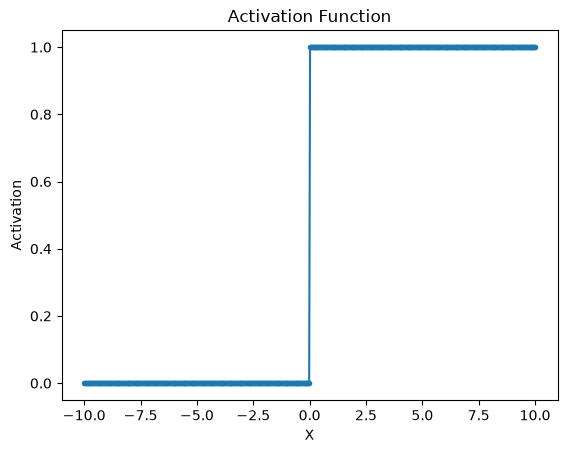

In [2]:
def Activation(s):
    if s > 0:
        activation = 1
    else:
        activation = 0
    return activation

in_array = np.linspace(-10, 10, 500)
out_array = []
for i in range(len(in_array)):
    out_array.append(Activation(in_array[i]))
out_array = np.array(out_array)
plt.plot(in_array, out_array, marker = ".")
plt.title("Activation Function")
plt.xlabel("X")
plt.ylabel("Activation")
plt.show()


In [28]:
class Perceptron(object):
    def __init__(self, numOfInputs, epochs=10000, learningRate=0.01):
        self.epochs = epochs
        self.learningRate = learningRate
        self.weights = np.zeros(numOfInputs)
        self.bias = 1

    def Activation(self, s):
        return np.where(s > 0, 1, 0)

    def Predict(self, inputs):
        sum = np.dot(inputs, self.weights) + self.bias
        out = self.Activation(sum)
        return out

    def Train(self, inputs, labels):
        for _ in range(self.epochs):
            for i in range(len(inputs)):
                prd = self.Predict(inputs[i])
                self.weights += (labels[i] - prd) * inputs[i] * self.learningRate
                self.bias += (labels[i] - prd) * self.learningRate

    def Accuracy(self, inputs, labels):
        predictions = self.Predict(inputs)
        accuracy = np.mean(predictions == labels)
        return accuracy

In [4]:
inputs = np.array([[0,0], [0,1], [1,0], [1, 1]])
labels = np.array([0, 1, 1, 0])
perceptron = Perceptron(2)
perceptron.Train(inputs, labels)
t1 = np.array([0, 0])
print(t1 , perceptron.Predict(t1))
t2 = np.array([0, 1])
print(t2 , perceptron.Predict(t2))
t3 = np.array([1, 0])
print(t3 , perceptron.Predict(t3))
t4 = np.array([1, 1])
print(t4 , perceptron.Predict(t4))

[0 0] 1
[0 1] 0
[1 0] 0
[1 1] 0


In [29]:
inputs = []
labels = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
# land = 0, sea = 1

for p in range(1, 11):
    filename = f"/Users/tapuz/Desktop/Engineering/Machine Learning/Perceptron/land/land{p}.jpg"
    img = Image.open(filename)
    img.load()
    arr = np.array(img, dtype=np.uint8)
    means = arr.mean(axis=(0, 1))
    inputs.append(means)

for p in range(1, 11):
    filename = f"/Users/tapuz/Desktop/Engineering/Machine Learning/Perceptron/sea/sea{p}.jpg"
    img = Image.open(filename)
    img.load()
    arr = np.array(img, dtype=np.uint8)
    means = arr.mean(axis=(0, 1))
    inputs.append(means)
    
inputs = np.array(inputs)
labels = np.array(labels)

perceptron = Perceptron(3)

perceptron.Train(inputs, labels)

acc = perceptron.Accuracy(inputs, labels)
print(f"Model Accuracy: {acc * 100:.2f}%")

Model Accuracy: 90.00%
